# [양자컴퓨팅 부트캠프] Day 2: 다중 큐비트, 텐서곱, 그리고 양자 얽힘(Entanglement) (정답 및 실행 결과)

이번 2부 실습에서는 1부에서 다룬 다중 큐비트 이론을 **순수 NumPy** 행렬 연산으로 직접 구현하고 검증합니다.

### 학습 목표 및 실습 구성
1. **[Lab 1] Kronecker Product($\otimes$)**: 4차원 계산 기저 생성, 혼합곱 성질 검증, $H \otimes I$ 연산자 구성 및 유니터리성 확인
2. **[Lab 2] CNOT($\mathrm{CX}$) 게이트와 Bell 상태**: $4 \times 4$ $\mathrm{CX}$ 행렬 정의 및 Bell 상태 생성
3. **[Lab 3] 2큐비트 순수 상태 비분리성 & 제어 반전 $\mathrm{CX}_{1\to 0}$**: 비분리성 조건($c_{00}c_{11}-c_{01}c_{10} \neq 0$) 판별 및 제어-타깃 반전 행렬 도출
4. **[Lab 4] 부분 측정(Partial Measurement)과 재정규화 (관찰)**: 중첩 유지 케이스 및 Bell 상태 붕괴 비교
5. **[Lab 5] 2큐비트 Shot 샘플링과 시각화 (관찰)**: 2,048 Shots 샘플링 및 빈도 히스토그램 비교
6. **[Lab 6] 3큐비트 GHZ vs W 상태 비교 (관찰)**: 붕괴 전 3큐비트 분포 vs $q_0=0$ 붕괴 후 남은 2큐비트 분포 시각화

In [1]:
from __future__ import annotations
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def _fmt_scalar(z: complex) -> str:
    if abs(z.imag) < 1e-10:
        r = z.real
        if abs(r) < 1e-10:
            return "0"
        special = [
            (1.0, "1"), (-1.0, "-1"), (0.5, "0.5"), (-0.5, "-0.5"),
            (1.0 / np.sqrt(2.0), r"\frac{1}{\sqrt{2}}"), (-1.0 / np.sqrt(2.0), r"-\frac{1}{\sqrt{2}}"),
            (1.0 / np.sqrt(3.0), r"\frac{1}{\sqrt{3}}"), (-1.0 / np.sqrt(3.0), r"-\frac{1}{\sqrt{3}}"),
        ]
        for val, tex in special:
            if abs(r - val) < 1e-8:
                return tex
        return f"{r:.4f}".rstrip("0").rstrip(".")
    return f"{z.real:.3f}{z.imag:+.3f}i"

def to_latex_matrix(arr: np.ndarray) -> str:
    a = np.atleast_2d(arr)
    rows = [" & ".join(_fmt_scalar(val) for val in row) for row in a]
    return r"\begin{pmatrix} " + r" \\ ".join(rows) + r" \end{pmatrix}"

# 기본 1큐비트 기저 및 유니터리 연산자 정의
KET_0 = np.array([[1.0], [0.0]], dtype=complex)
KET_1 = np.array([[0.0], [1.0]], dtype=complex)

GATE_I = np.eye(2, dtype=complex)
GATE_X = np.array([[0, 1], [1, 0]], dtype=complex)
GATE_Z = np.array([[1, 0], [0, -1]], dtype=complex)
GATE_H = (1.0 / np.sqrt(2.0)) * np.array([[1, 1], [1, -1]], dtype=complex)

display(Markdown(
    f"**1큐비트 기본 기저 및 연산자 세팅 완료**\n\n"
    f"$$|0\\rangle = {to_latex_matrix(KET_0)},\\quad |1\\rangle = {to_latex_matrix(KET_1)}$$\n"
    f"$$I = {to_latex_matrix(GATE_I)},\\quad X = {to_latex_matrix(GATE_X)},\\quad "
    f"Z = {to_latex_matrix(GATE_Z)},\\quad H = {to_latex_matrix(GATE_H)}$$"
))

**1큐비트 기본 기저 및 연산자 세팅 완료**

$$|0\rangle = \begin{pmatrix} 1 \\ 0 \end{pmatrix},\quad |1\rangle = \begin{pmatrix} 0 \\ 1 \end{pmatrix}$$
$$I = \begin{pmatrix} 1 & 0 \\ 0 & 1 \end{pmatrix},\quad X = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix},\quad Z = \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix},\quad H = \begin{pmatrix} \frac{1}{\sqrt{2}} & \frac{1}{\sqrt{2}} \\ \frac{1}{\sqrt{2}} & -\frac{1}{\sqrt{2}} \end{pmatrix}$$

## [Lab 1] Kronecker Product($\otimes$), 혼합곱 성질, 그리고 $H \otimes I$

NumPy의 `np.kron(A, B)` 함수는 임의 크기 행렬의 Kronecker Product($A \otimes B$)를 계산합니다.
1. **과제 1-1**: 4차원 계산 기저 $|00\rangle, |01\rangle, |10\rangle, |11\rangle$를 생성하세요.
2. **과제 1-2**: 혼합곱 성질 $(H \otimes X)(Z \otimes H) = (HZ) \otimes (XH)$가 수치적으로 일치하는지 좌변(`lhs`)과 우변(`rhs`)을 각각 계산해 검증하세요.
3. **과제 1-3**: $q_0$에만 $H$를 적용하는 연산자 `H_I`($H \otimes I$)를 구성하고, 4대 계산 기저에 적용한 결과 및 유니터리성($U^* U = I_4$)을 확인하세요.

In [2]:
# [실습 과제 1-1] np.kron을 사용하여 2큐비트 계산 기저 열벡터를 완성하세요.
KET_00 = np.kron(KET_0, KET_0)
KET_01 = np.kron(KET_0, KET_1)
KET_10 = np.kron(KET_1, KET_0)
KET_11 = np.kron(KET_1, KET_1)

# [실습 과제 1-2] 혼합곱 공식 (H ⊗ X)(Z ⊗ H) == (HZ) ⊗ (XH)의 좌변과 우변을 각각 작성하세요.
lhs = np.kron(GATE_H, GATE_X) @ np.kron(GATE_Z, GATE_H)
rhs = np.kron(GATE_H @ GATE_Z, GATE_X @ GATE_H)

# [실습 과제 1-3] H_I (H ⊗ I) 행렬을 구성하세요.
H_I = np.kron(GATE_H, GATE_I)

# [자가 검증] 아래 코드를 실행해 확인하세요 (수정 불필요)
assert KET_01 is not None and np.allclose(KET_01, [[0], [1], [0], [0]]), 'KET_01 정의 오류!'
assert KET_10 is not None and np.allclose(KET_10, [[0], [0], [1], [0]]), 'KET_10 정의 오류!'
assert KET_11 is not None and np.allclose(KET_11, [[0], [0], [0], [1]]), 'KET_11 정의 오류!'
assert lhs is not None and rhs is not None and np.allclose(lhs, rhs), '혼합곱 공식 불일치!'
assert H_I is not None and H_I.shape == (4, 4), 'H_I는 4x4 행렬이어야 합니다!'
assert np.allclose(H_I.conj().T @ H_I, np.eye(4, dtype=complex)), 'H_I가 유니터리하지 않습니다!'
assert np.allclose(H_I @ KET_01, (1/np.sqrt(2)) * (KET_01 + KET_11)), '(H⊗I)|01> 결과 불일치!'

hi_ket01 = H_I @ KET_01
display(Markdown(
    f"**[Lab 1 결과]**\n\n"
    f"1. **2큐비트 계산 기저**:\n"
    f"$$|00\\rangle = {to_latex_matrix(KET_00)},\\quad |01\\rangle = {to_latex_matrix(KET_01)},\\quad "
    f"|10\\rangle = {to_latex_matrix(KET_10)},\\quad |11\\rangle = {to_latex_matrix(KET_11)}$$\n"
    f"2. **혼합곱 성질** $(H\\otimes X)(Z\\otimes H) = (HZ)\\otimes(XH)$ (최대 오차 `{np.max(np.abs(lhs - rhs)):.1e}`):\n"
    f"$${to_latex_matrix(lhs)} = {to_latex_matrix(rhs)}$$\n"
    f"3. **$H\\otimes I$ 연산자 및 $|01\\rangle$ 적용 결과**:\n"
    f"$$H\\otimes I = {to_latex_matrix(H_I)},\\qquad (H\\otimes I)|01\\rangle = {to_latex_matrix(hi_ket01)} = |+\\rangle\\otimes|1\\rangle$$"
))

**[Lab 1 결과]**

1. **2큐비트 계산 기저**:
$$|00\rangle = \begin{pmatrix} 1 \\ 0 \\ 0 \\ 0 \end{pmatrix},\quad |01\rangle = \begin{pmatrix} 0 \\ 1 \\ 0 \\ 0 \end{pmatrix},\quad |10\rangle = \begin{pmatrix} 0 \\ 0 \\ 1 \\ 0 \end{pmatrix},\quad |11\rangle = \begin{pmatrix} 0 \\ 0 \\ 0 \\ 1 \end{pmatrix}$$
2. **혼합곱 성질** $(H\otimes X)(Z\otimes H) = (HZ)\otimes(XH)$ (최대 오차 `0.0e+00`):
$$\begin{pmatrix} 0.5 & -0.5 & -0.5 & 0.5 \\ 0.5 & 0.5 & -0.5 & -0.5 \\ 0.5 & -0.5 & 0.5 & -0.5 \\ 0.5 & 0.5 & 0.5 & 0.5 \end{pmatrix} = \begin{pmatrix} 0.5 & -0.5 & -0.5 & 0.5 \\ 0.5 & 0.5 & -0.5 & -0.5 \\ 0.5 & -0.5 & 0.5 & -0.5 \\ 0.5 & 0.5 & 0.5 & 0.5 \end{pmatrix}$$
3. **$H\otimes I$ 연산자 및 $|01\rangle$ 적용 결과**:
$$H\otimes I = \begin{pmatrix} \frac{1}{\sqrt{2}} & 0 & \frac{1}{\sqrt{2}} & 0 \\ 0 & \frac{1}{\sqrt{2}} & 0 & \frac{1}{\sqrt{2}} \\ \frac{1}{\sqrt{2}} & 0 & -\frac{1}{\sqrt{2}} & 0 \\ 0 & \frac{1}{\sqrt{2}} & 0 & -\frac{1}{\sqrt{2}} \end{pmatrix},\qquad (H\otimes I)|01\rangle = \begin{pmatrix} 0 \\ \frac{1}{\sqrt{2}} \\ 0 \\ \frac{1}{\sqrt{2}} \end{pmatrix} = |+\rangle\otimes|1\rangle$$

## [Lab 2] $4 \times 4$ CNOT($\mathrm{CX}$) 게이트와 Bell 상태 생성

$q_0$을 제어(Control), $q_1$을 타깃(Target)으로 하는 기본형 CNOT 행렬 $\mathrm{CX}$를 직접 정의하고, 2단계 Bell 회로를 실행해 $|\Phi^+\rangle = \frac{|00\rangle+|11\rangle}{\sqrt{2}}$가 생성됨을 확인합니다.

- **과제 2-1**: 기저 매핑($|00\rangle\mapsto|00\rangle, |01\rangle\mapsto|01\rangle, |10\rangle\mapsto|11\rangle, |11\rangle\mapsto|10\rangle$)에 맞는 $4\times 4$ `GATE_CNOT` 행렬을 정의하세요.
- **과제 2-2**: $(H \otimes I)|00\rangle$(`psi_step1`)과 $\mathrm{CX}|\psi_1\rangle$(`psi_bell`)을 순서대로 계산하세요.

In [3]:
# [실습 과제 2-1] 4x4 CNOT 행렬을 정의하세요 (dtype=complex 권장).
# 힌트: |00>->|00>, |01>->|01>, |10>->|11>, |11>->|10>
GATE_CNOT = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=complex)

# [실습 과제 2-2] Bell 회로 2단계 연산을 순서대로 수행하세요.
psi_step1 = H_I @ KET_00
psi_bell = GATE_CNOT @ psi_step1

# [자가 검증] 1부 수식 계산 결과와 1:1 대조 (수정 불필요)
expected_step1 = (1.0 / np.sqrt(2.0)) * (KET_00 + KET_10)
expected_bell = (1.0 / np.sqrt(2.0)) * (KET_00 + KET_11)
assert GATE_CNOT is not None and GATE_CNOT.shape == (4, 4), 'CNOT은 4x4 행렬이어야 합니다!'
assert np.allclose(GATE_CNOT.conj().T @ GATE_CNOT, np.eye(4)), 'CNOT이 유니터리하지 않습니다!'
assert psi_step1 is not None and np.allclose(psi_step1, expected_step1), '1단계 상태(|+0>) 오류!'
assert psi_bell is not None and np.allclose(psi_bell, expected_bell), '수식 계산 Bell 상태와 불일치!'

probs_bell = np.abs(psi_bell.flatten()) ** 2
display(Markdown(
    f"**[Lab 2 결과]**\n\n"
    f"1. **$4\\times 4$ CNOT 행렬**:\n"
    f"$$\\mathrm{{CX}} = {to_latex_matrix(GATE_CNOT)}$$\n"
    f"2. **Bell 회로 단계별 상태 변화**:\n"
    f"$$|\\psi_1\\rangle = (H\\otimes I)|00\\rangle = {to_latex_matrix(psi_step1)},\\qquad "
    f"|\\psi_2\\rangle = \\mathrm{{CX}}|\\psi_1\\rangle = {to_latex_matrix(psi_bell)} = |\\Phi^+\\rangle$$\n"
    f"3. **기저별 관측 확률**: `00`: `{probs_bell[0]*100:.1f}%`, `01`: `{probs_bell[1]*100:.1f}%`, "
    f"`10`: `{probs_bell[2]*100:.1f}%`, `11`: `{probs_bell[3]*100:.1f}%`"
))

**[Lab 2 결과]**

1. **$4\times 4$ CNOT 행렬**:
$$\mathrm{CX} = \begin{pmatrix} 1 & 0 & 0 & 0 \\ 0 & 1 & 0 & 0 \\ 0 & 0 & 0 & 1 \\ 0 & 0 & 1 & 0 \end{pmatrix}$$
2. **Bell 회로 단계별 상태 변화**:
$$|\psi_1\rangle = (H\otimes I)|00\rangle = \begin{pmatrix} \frac{1}{\sqrt{2}} \\ 0 \\ \frac{1}{\sqrt{2}} \\ 0 \end{pmatrix},\qquad |\psi_2\rangle = \mathrm{CX}|\psi_1\rangle = \begin{pmatrix} \frac{1}{\sqrt{2}} \\ 0 \\ 0 \\ \frac{1}{\sqrt{2}} \end{pmatrix} = |\Phi^+\rangle$$
3. **기저별 관측 확률**: `00`: `50.0%`, `01`: `0.0%`, `10`: `0.0%`, `11`: `50.0%`

## [Lab 3-1] 2큐비트 순수 상태 비분리성 판별 ($|c_{00}c_{11} - c_{01}c_{10}|$)

2큐비트 순수 상태 $|\psi\rangle = c_{00}|00\rangle + c_{01}|01\rangle + c_{10}|10\rangle + c_{11}|11\rangle$가 곱상태 $(\alpha|0\rangle+\beta|1\rangle)\otimes(\gamma|0\rangle+\delta|1\rangle)$로 인수분해된다면, $c_{00}c_{11} = c_{01}c_{10}$이므로 $c_{00}c_{11} - c_{01}c_{10} = 0$이 성립합니다.

> **적용 범위 주의**: 위 조건($c_{00}c_{11} - c_{01}c_{10} \neq 0$)은 **2큐비트 순수 상태**에 한해 성립하는 판별식이며, 3큐비트 이상 다중 큐비트 얽힘에는 적용되지 않습니다.

- **과제 3-1**: `psi_step1`, `psi_bell`, 그리고 겉보기에 중첩된 미지 상태 `psi_A`($|++\rangle$)와 `psi_B`($|\Psi^-\rangle$)에 대해 $|c_{00}c_{11}-c_{01}c_{10}|$ 값을 직접 계산해 곱상태와 얽힘 상태를 판별하세요.

In [4]:
# [실습 과제 3-1] 2큐비트 순수 상태 비분리성 판별값 |c00*c11 - c01*c10|을 직접 계산하세요.
# 비교용 미지 상태 2종:
psi_A = 0.5 * (KET_00 + KET_01 + KET_10 + KET_11)          # 균일 중첩 |++>
psi_B = (1.0 / np.sqrt(2.0)) * (KET_01 - KET_10)           # 단일항 |Psi->

def _nonsep_gap(state_4d: np.ndarray) -> float:
    v = state_4d.flatten()
    return float(abs(v[0] * v[3] - v[1] * v[2]))

# 아래 빈칸에 각 상태의 |c00*c11 - c01*c10| 값을 계산하는 식을 채우세요 (예: abs(v[0]*v[3] - v[1]*v[2])).
v1 = psi_step1.flatten()
gap_step1 = float(abs(v1[0] * v1[3] - v1[1] * v1[2]))

vb = psi_bell.flatten()
gap_bell = float(abs(vb[0] * vb[3] - vb[1] * vb[2]))

vA = psi_A.flatten()
gap_A = float(abs(vA[0] * vA[3] - vA[1] * vA[2]))

vB = psi_B.flatten()
gap_B = float(abs(vB[0] * vB[3] - vB[1] * vB[2]))

# [자가 검증] (수정 불필요)
assert gap_step1 is not None and np.isclose(gap_step1, 0.0), 'Step 1 상태(|+0>)는 곱상태(0)여야 합니다.'
assert gap_bell is not None and np.isclose(gap_bell, 0.5), 'Bell 상태(|Phi+>)는 최대 얽힘(0.5)이어야 합니다.'
assert gap_A is not None and np.isclose(gap_A, 0.0), '|++> 상태는 4개 항이 있어도 곱상태(0)입니다.'
assert gap_B is not None and np.isclose(gap_B, 0.5), '|Psi-> 상태는 최대 얽힘(0.5)입니다.'

display(Markdown(
    f"**[Lab 3-1 결과] 2큐비트 순수 상태 비분리성 판별 ($\\lvert c_{{00}}c_{{11}} - c_{{01}}c_{{10}}\\rvert$)**\n\n"
    f"| 대상 상태 | $\\lvert c_{{00}}c_{{11}} - c_{{01}}c_{{10}}\\rvert$ | 판별 결과 |\n"
    f"| :--- | :---: | :--- |\n"
    f"| `psi_step1` ($\\lvert+0\\rangle$) | `{gap_step1:.4f}` | {'얽힘 상태' if gap_step1 > 1e-9 else '곱상태 (분리 가능)'} |\n"
    f"| `psi_bell` ($\\lvert\\Phi^+\\rangle$) | `{gap_bell:.4f}` | {'얽힘 상태 (최대 얽힘)' if gap_bell > 1e-9 else '곱상태'} |\n"
    f"| `psi_A` ($\\lvert ++\\rangle$) | `{gap_A:.4f}` | {'얽힘 상태' if gap_A > 1e-9 else '곱상태 (분리 가능)'} |\n"
    f"| `psi_B` ($\\lvert\\Psi^-\\rangle$) | `{gap_B:.4f}` | {'얽힘 상태 (최대 얽힘)' if gap_B > 1e-9 else '곱상태'} |"
))

**[Lab 3-1 결과] 2큐비트 순수 상태 비분리성 판별 ($\lvert c_{00}c_{11} - c_{01}c_{10}\rvert$)**

| 대상 상태 | $\lvert c_{00}c_{11} - c_{01}c_{10}\rvert$ | 판별 결과 |
| :--- | :---: | :--- |
| `psi_step1` ($\lvert+0\rangle$) | `0.0000` | 곱상태 (분리 가능) |
| `psi_bell` ($\lvert\Phi^+\rangle$) | `0.5000` | 얽힘 상태 (최대 얽힘) |
| `psi_A` ($\lvert ++\rangle$) | `0.0000` | 곱상태 (분리 가능) |
| `psi_B` ($\lvert\Psi^-\rangle$) | `0.5000` | 얽힘 상태 (최대 얽힘) |

## [Lab 3-2] 제어 반전 $\mathrm{CX}_{1\to 0}$ 행렬 구성 및 대칭 Bell 회로

회로 설계에 따라 제어와 타깃의 위치가 뒤바뀔 수 있습니다. $q_1$이 제어(Control), $q_0$이 타깃(Target)인 반전 CNOT 행렬을 구성하고, $(I\otimes H)|00\rangle$ 뒤에 적용해도 동일한 Bell 상태 $|\Phi^+\rangle$가 생성되는지 확인합니다.

- **과제 3-2**: 기저 매핑($|00\rangle\mapsto|00\rangle, |01\rangle\mapsto|11\rangle, |10\rangle\mapsto|10\rangle, |11\rangle\mapsto|01\rangle$)에 맞는 $4\times 4$ `GATE_CNOT_REV` 행렬을 정의하세요.

In [5]:
# [실습 과제 3-2] q1이 제어(Control), q0이 타깃(Target)인 반전 CNOT (CX_{1->0}) 행렬을 구성하세요.
# 힌트: |00>->|00>, |01>->|11>, |10>->|10>, |11>->|01>
GATE_CNOT_REV = np.array([[1, 0, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0], [0, 1, 0, 0]], dtype=complex)

# 반전된 회로: q1에 H를 먼저 걸고 (I ⊗ H), 반전 CNOT (CX_{1->0}) 적용
I_H = np.kron(GATE_I, GATE_H)
psi_bell_from_rev = GATE_CNOT_REV @ (I_H @ KET_00)

# [자가 검증] (수정 불필요)
assert GATE_CNOT_REV is not None and GATE_CNOT_REV.shape == (4, 4), '4x4 행렬을 정의하세요!'
assert np.allclose(GATE_CNOT_REV @ KET_01, KET_11), 'q1=1일 때 q0이 반전(|01>->|11>)되어야 합니다!'
assert np.allclose(GATE_CNOT_REV @ KET_11, KET_01), 'q1=1일 때 q0이 반전(|11>->|01>)되어야 합니다!'
assert np.allclose(GATE_CNOT_REV @ KET_10, KET_10), 'q1=0일 때 상태가 유지(|10>->|10>)되어야 합니다!'
assert psi_bell_from_rev is not None and np.allclose(psi_bell_from_rev, psi_bell), '반전 회로로도 |Phi+>가 생성되어야 합니다!'

display(Markdown(
    f"**[Lab 3-2 결과] 제어 반전 $\\mathrm{{CX}}_{{1\\to 0}}$ 행렬 및 대칭 Bell 회로 확인**\n\n"
    f"$$\\mathrm{{CX}}_{{1\\to 0}} = {to_latex_matrix(GATE_CNOT_REV)},\\qquad "
    f"\\mathrm{{CX}}_{{1\\to 0}}(I\\otimes H)|00\\rangle = {to_latex_matrix(psi_bell_from_rev)} = |\\Phi^+\\rangle$$"
))

**[Lab 3-2 결과] 제어 반전 $\mathrm{CX}_{1\to 0}$ 행렬 및 대칭 Bell 회로 확인**

$$\mathrm{CX}_{1\to 0} = \begin{pmatrix} 1 & 0 & 0 & 0 \\ 0 & 0 & 0 & 1 \\ 0 & 0 & 1 & 0 \\ 0 & 1 & 0 & 0 \end{pmatrix},\qquad \mathrm{CX}_{1\to 0}(I\otimes H)|00\rangle = \begin{pmatrix} \frac{1}{\sqrt{2}} \\ 0 \\ 0 \\ \frac{1}{\sqrt{2}} \end{pmatrix} = |\Phi^+\rangle$$

## [Lab 4: 실행 및 관찰] 부분 측정(Partial Measurement)과 재정규화

아래 두 상태를 대상으로 첫 번째 큐비트 $q_0$만 부분 측정했을 때 남은 $q_1$의 상태 변화를 비교합니다:

$$|\psi\rangle = 0.5|00\rangle + 0.5|01\rangle + \frac{1}{\sqrt{2}}|10\rangle \qquad\text{vs}\qquad |\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$$

$q_0$만 측정하면 다음 3단계가 일어납니다:
1. **성분 추출**: 관측된 $q_0$ 값에 해당하는 2개 성분(`0`이면 `[:2]`, `1`이면 `[2:]`)만 남습니다.
2. **확률 계산**: 추출한 부분 벡터 크기의 제곱합 $P$가 해당 결과가 나올 확률입니다.
3. **재정규화**: 남은 벡터를 $\sqrt{P}$ (`norm`)로 나누어 크기 $1$인 유효한 상태벡터로 복구합니다.

아래 셀을 **실행(`Shift+Enter`)**하여 예시 상태($q_1$ 중첩 유지)와 Bell 상태($q_1$ 즉각 붕괴)의 차이를 표로 확인해 보세요.

In [6]:
# [Lab 4: 실행 및 관찰] 부분 측정(Partial Measurement)의 사영 추출 및 재정규화
# 1부 예시 상태: |psi> = 0.5|00> + 0.5|01> + (1/sqrt(2))|10>
psi_example = 0.5 * KET_00 + 0.5 * KET_01 + (1.0 / np.sqrt(2.0)) * KET_10

# 예시 상태: q0=0 관측 시 앞 2개 성분([:2]) 추출 -> 확률 계산 -> norm으로 나눠 재정규화
sub_ex0 = psi_example[:2]
p_ex0 = float(np.sum(np.abs(sub_ex0) ** 2))
q1_ex0 = sub_ex0 / np.linalg.norm(sub_ex0)

sub_ex1 = psi_example[2:]
p_ex1 = float(np.sum(np.abs(sub_ex1) ** 2))
q1_ex1 = sub_ex1 / np.linalg.norm(sub_ex1)

# Bell 상태 |Phi+>: q0=0 관측([:2]) 및 q0=1 관측([2:]) 후 남은 q1 상태 계산
sub_b0 = psi_bell[:2]
p_b0 = float(np.sum(np.abs(sub_b0) ** 2))
q1_b0 = sub_b0 / np.linalg.norm(sub_b0)

sub_b1 = psi_bell[2:]
p_b1 = float(np.sum(np.abs(sub_b1) ** 2))
q1_b1 = sub_b1 / np.linalg.norm(sub_b1)

assert np.isclose(p_ex0, 0.5) and np.allclose(q1_ex0, (KET_0 + KET_1) / np.sqrt(2.0))
assert np.isclose(p_ex1, 0.5) and np.allclose(q1_ex1, KET_0)
assert np.allclose(q1_b0, KET_0) and np.allclose(q1_b1, KET_1)

display(Markdown(
    f"**[Lab 4 관찰 결과] $q_0$ 부분 측정 후 남은 $q_1$의 재정규화 상태**\n\n"
    f"| 대상 상태 | $q_0$ 관측 결과 | 관측 확률 | 붕괴 전 부분 벡터 | 재정규화 후 $q_1$ 상태 | 물리적 해석 |\n"
    f"| :--- | :---: | :---: | :---: | :---: | :--- |\n"
    f"| 예시 상태 $\\lvert\\psi\\rangle$ | `0` | `{p_ex0*100:.1f}%` | ${to_latex_matrix(sub_ex0)}$ | ${to_latex_matrix(q1_ex0)} = \\lvert +\\rangle$ | $q_1$의 **중첩 유지** |\n"
    f"| 예시 상태 $\\lvert\\psi\\rangle$ | `1` | `{p_ex1*100:.1f}%` | ${to_latex_matrix(sub_ex1)}$ | ${to_latex_matrix(q1_ex1)} = \\lvert 0\\rangle$ | $q_1$이 `0`으로 확정 |\n"
    f"| Bell 상태 $\\lvert\\Phi^+\\rangle$ | `0` | `{p_b0*100:.1f}%` | ${to_latex_matrix(sub_b0)}$ | ${to_latex_matrix(q1_b0)} = \\lvert 0\\rangle$ | 즉각 `0`으로 붕괴 |\n"
    f"| Bell 상태 $\\lvert\\Phi^+\\rangle$ | `1` | `{p_b1*100:.1f}%` | ${to_latex_matrix(sub_b1)}$ | ${to_latex_matrix(q1_b1)} = \\lvert 1\\rangle$ | 즉각 `1`로 붕괴 |"
))

**[Lab 4 관찰 결과] $q_0$ 부분 측정 후 남은 $q_1$의 재정규화 상태**

| 대상 상태 | $q_0$ 관측 결과 | 관측 확률 | 붕괴 전 부분 벡터 | 재정규화 후 $q_1$ 상태 | 물리적 해석 |
| :--- | :---: | :---: | :---: | :---: | :--- |
| 예시 상태 $\lvert\psi\rangle$ | `0` | `50.0%` | $\begin{pmatrix} 0.5 \\ 0.5 \end{pmatrix}$ | $\begin{pmatrix} \frac{1}{\sqrt{2}} \\ \frac{1}{\sqrt{2}} \end{pmatrix} = \lvert +\rangle$ | $q_1$의 **중첩 유지** |
| 예시 상태 $\lvert\psi\rangle$ | `1` | `50.0%` | $\begin{pmatrix} \frac{1}{\sqrt{2}} \\ 0 \end{pmatrix}$ | $\begin{pmatrix} 1 \\ 0 \end{pmatrix} = \lvert 0\rangle$ | $q_1$이 `0`으로 확정 |
| Bell 상태 $\lvert\Phi^+\rangle$ | `0` | `50.0%` | $\begin{pmatrix} \frac{1}{\sqrt{2}} \\ 0 \end{pmatrix}$ | $\begin{pmatrix} 1 \\ 0 \end{pmatrix} = \lvert 0\rangle$ | 즉각 `0`으로 붕괴 |
| Bell 상태 $\lvert\Phi^+\rangle$ | `1` | `50.0%` | $\begin{pmatrix} 0 \\ \frac{1}{\sqrt{2}} \end{pmatrix}$ | $\begin{pmatrix} 0 \\ 1 \end{pmatrix} = \lvert 1\rangle$ | 즉각 `1`로 붕괴 |

## [Lab 5: 실행 및 관찰] 2큐비트 Born 규칙 기반 2,048 Shots 샘플링 및 시각화

Born 규칙 $P(x) = |c_x|^2$에 따라 두 상태를 각각 **2,048번(2,048 Shots)** 반복 측정한 분포를 비교합니다:
- **분리 상태 $|++\rangle = (H\otimes H)|00\rangle$**: $q_0$과 $q_1$이 서로 독립인 동전처럼 움직여 `00, 01, 10, 11`이 각각 약 25%씩 고르게 관측됩니다.
- **얽힘 상태 $|\Phi^+\rangle$**: 두 큐비트의 측정 결과가 항상 일치해 `00`과 `11`만 약 50%씩 관측되고, `01`과 `10`은 단 1번도 나오지 않습니다.

아래 셀을 **실행(`Shift+Enter`)**하여 1 Shot 단일 출력과 2,048 Shots 빈도 비교 그래프를 확인해 보세요.

**[Lab 5 관찰 결과] 1 Shot 출력 (`11`) 및 2,048 Shots 빈도 비교**

| 비트열 | 분리 상태 $\lvert ++\rangle$ (독립 주사위) | 얽힘 상태 $\lvert\Phi^+\rangle$ (제어된 주사위) |
| :---: | :---: | :---: |
| `00` | 501 (24.5%) | 995 (48.6%) |
| `01` | 504 (24.6%) | 0 (0.0%) |
| `10` | 544 (26.6%) | 0 (0.0%) |
| `11` | 499 (24.4%) | 1053 (51.4%) |

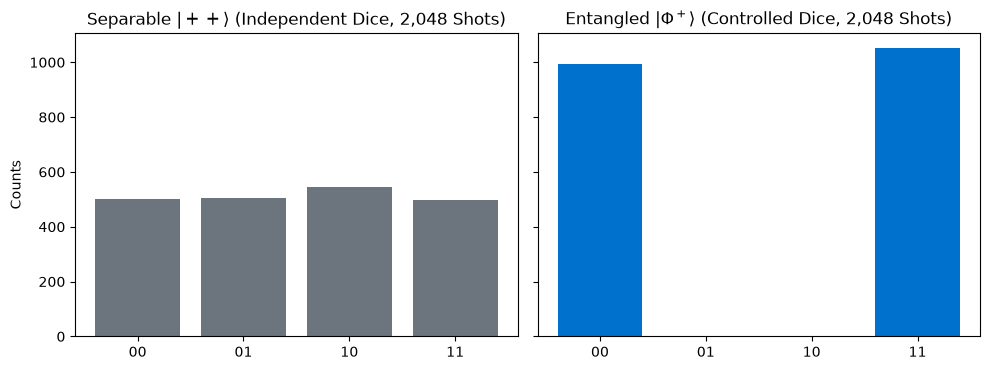

In [7]:
# [Lab 5: 실행 및 관찰] 2큐비트 Born 규칙 기반 2,048 Shots 샘플링 및 시각화
labels = ['00', '01', '10', '11']
shots = 2048

# 비교 대상 1: 분리 상태 |++> = (H ⊗ H)|00>
psi_plus_plus = np.kron(GATE_H, GATE_H) @ KET_00
probs_random = np.abs(psi_plus_plus.flatten()) ** 2
probs_random = probs_random / np.sum(probs_random)

# 비교 대상 2: 얽힘 상태 |Phi+> = psi_bell
probs_bell = np.abs(psi_bell.flatten()) ** 2
probs_bell = probs_bell / np.sum(probs_bell)

# 1 Shot 단일 측정 예시 & 2,048 Shots 반복 측정
single_shot = str(np.random.choice(labels, p=probs_bell))
samples_random = np.random.choice(labels, size=shots, p=probs_random)
samples_bell = np.random.choice(labels, size=shots, p=probs_bell)

counts_random = {lbl: int(np.sum(samples_random == lbl)) for lbl in labels}
counts_bell = {lbl: int(np.sum(samples_bell == lbl)) for lbl in labels}
assert counts_bell['01'] == 0 and counts_bell['10'] == 0, 'Bell 상태에서 01, 10이 나오면 안 됩니다!'

rows = "\n".join(
    f"| `{lbl}` | {counts_random[lbl]} ({counts_random[lbl]/shots*100:.1f}%) | {counts_bell[lbl]} ({counts_bell[lbl]/shots*100:.1f}%) |"
    for lbl in labels
)
display(Markdown(
    f"**[Lab 5 관찰 결과] 1 Shot 출력 (`{single_shot}`) 및 2,048 Shots 빈도 비교**\n\n"
    f"| 비트열 | 분리 상태 $\\lvert ++\\rangle$ (독립 주사위) | 얽힘 상태 $\\lvert\\Phi^+\\rangle$ (제어된 주사위) |\n"
    f"| :---: | :---: | :---: |\n"
    f"{rows}"
))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
axes[0].bar(counts_random.keys(), counts_random.values(), color='#6c757d')
axes[0].set_title(r'Separable $|++\rangle$ (Independent Dice, 2,048 Shots)')
axes[0].set_ylabel('Counts')
axes[1].bar(counts_bell.keys(), counts_bell.values(), color='#0072ce')
axes[1].set_title(r'Entangled $|\Phi^+\rangle$ (Controlled Dice, 2,048 Shots)')
plt.tight_layout()
plt.show()

## [Lab 6: 실행 및 관찰] 3큐비트 GHZ vs W: 붕괴 전/후 측정 분포 시각화

3큐비트 이상에서는 얽힘 여부뿐 아니라, **1개 큐비트($q_0$)가 측정으로 붕괴했을 때 남은 $(q_1, q_2)$의 구조가 어떻게 달라지는지**까지 확인해야 합니다:
- **GHZ 상태** $\frac{|000\rangle + |111\rangle}{\sqrt{2}}$: 붕괴 전에는 `000`과 `111`이 반반 나오지만, $q_0=0$으로 붕괴하는 순간 남은 $(q_1, q_2)$는 **곱상태 $|00\rangle$**으로 쪼개져 `00` 한 곳에만 100% 몰립니다(얽힘 소멸).
- **W 상태** $\frac{|001\rangle + |010\rangle + |100\rangle}{\sqrt{3}}$: 붕괴 전에는 `001, 010, 100`이 1/3씩 나오며, $q_0=0$으로 붕괴하더라도 남은 $(q_1, q_2)$는 **Bell 상태 $\frac{|01\rangle+|10\rangle}{\sqrt{2}}$**를 유지하여 `01`과 `10`이 50:50으로 관측됩니다(얽힘 유지).

아래 셀을 **실행(`Shift+Enter`)**하여 붕괴 전 3큐비트 분포(왼쪽)와 $q_0=0$ 붕괴 후 남은 2큐비트 분포(오른쪽)를 직접 비교해 보세요.

**[Lab 6 관찰 결과] 3큐비트 GHZ vs W: 붕괴 전/후 측정 분포 및 얽힘 구조 비교**

| 3큐비트 상태 | $q_0=0$ 붕괴 후 $(q_1, q_2)$ 벡터 | $\lvert c_{00}c_{11}-c_{01}c_{10}\rvert$ | 얽힘 상태 |
| :--- | :---: | :---: | :--- |
| GHZ | $\begin{pmatrix} 1 \\ 0 \\ 0 \\ 0 \end{pmatrix}$ | `0.0000` | 소멸 (곱상태 $\lvert 00\rangle$) |
| W | $\begin{pmatrix} 0 \\ \frac{1}{\sqrt{2}} \\ \frac{1}{\sqrt{2}} \\ 0 \end{pmatrix}$ | `0.5000` | 유지 (Bell 상태 $\lvert\Psi^+\rangle$) |

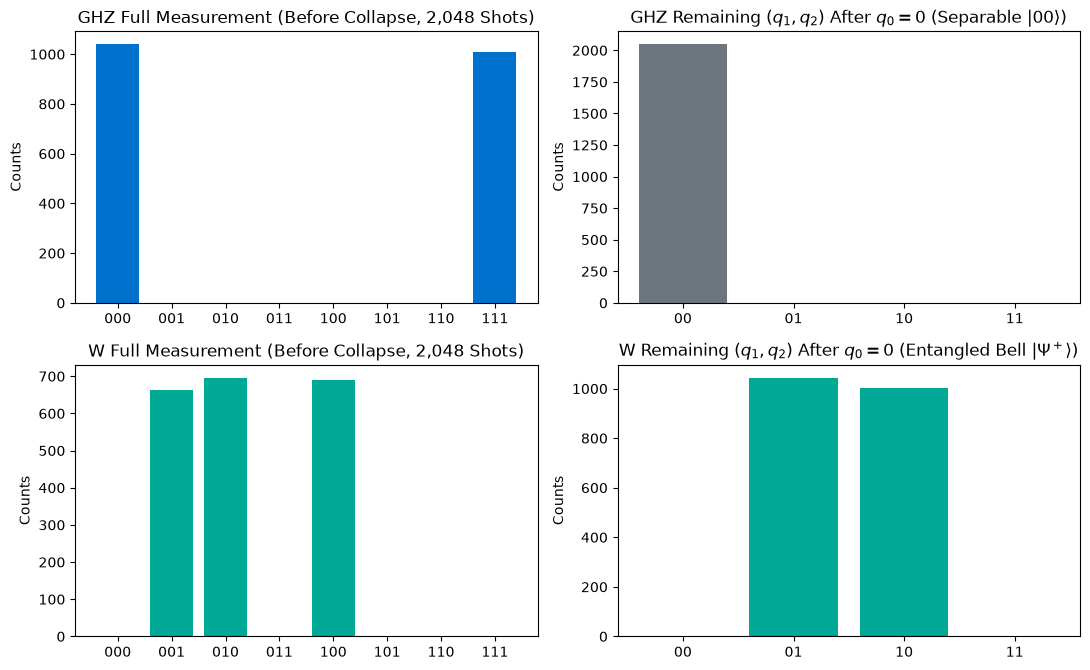

In [8]:
# [Lab 6: 실행 및 관찰] 3큐비트 GHZ vs W: 붕괴 전 전체 측정 vs q0=0 붕괴 후 나머지 측정 분포 시각화
from functools import reduce

def kron_all(*mats: np.ndarray) -> np.ndarray:
    return reduce(np.kron, mats)

def collapse_q0_zero_3q(state_8d: np.ndarray) -> np.ndarray:
    sub = state_8d.flatten()[:4]
    return sub / np.linalg.norm(sub)

# 1. 3큐비트 GHZ 상태 및 W 상태 생성
ket_000 = kron_all(KET_0, KET_0, KET_0)
psi_ghz = kron_all(GATE_I, GATE_CNOT) @ kron_all(GATE_CNOT, GATE_I) @ kron_all(GATE_H, GATE_I, GATE_I) @ ket_000
psi_w = (
    kron_all(KET_0, KET_0, KET_1)
    + kron_all(KET_0, KET_1, KET_0)
    + kron_all(KET_1, KET_0, KET_0)
) / np.sqrt(3.0)

# 2. q0=0 부분 측정 후 남은 (q1, q2) 4차원 상태벡터
ghz_after_0 = collapse_q0_zero_3q(psi_ghz)
w_after_0 = collapse_q0_zero_3q(psi_w)
gap_ghz = float(abs(ghz_after_0[0] * ghz_after_0[3] - ghz_after_0[1] * ghz_after_0[2]))
gap_w = float(abs(w_after_0[0] * w_after_0[3] - w_after_0[1] * w_after_0[2]))

assert np.isclose(gap_ghz, 0.0) and np.isclose(gap_w, 0.5)

# 3. 2,048 Shots 샘플링: 붕괴 없는 3큐비트 전체 측정 vs q0=0 붕괴 후 남은 (q1, q2) 측정
shots = 2048
labels_3q = ['000', '001', '010', '011', '100', '101', '110', '111']
labels_2q = ['00', '01', '10', '11']

def _sample_counts(state_vec: np.ndarray, lbls: list, n_shots: int) -> dict:
    p = np.abs(state_vec.flatten()) ** 2
    p = p / np.sum(p)
    samp = np.random.choice(lbls, size=n_shots, p=p)
    return {lbl: int(np.sum(samp == lbl)) for lbl in lbls}

c_ghz_full = _sample_counts(psi_ghz, labels_3q, shots)
c_ghz_sub = _sample_counts(ghz_after_0, labels_2q, shots)
c_w_full = _sample_counts(psi_w, labels_3q, shots)
c_w_sub = _sample_counts(w_after_0, labels_2q, shots)

ghz_status = r'소멸 (곱상태 $\lvert 00\rangle$)'
w_status = r'유지 (Bell 상태 $\lvert\Psi^+\rangle$)'
display(Markdown(
    f"**[Lab 6 관찰 결과] 3큐비트 GHZ vs W: 붕괴 전/후 측정 분포 및 얽힘 구조 비교**\n\n"
    f"| 3큐비트 상태 | $q_0=0$ 붕괴 후 $(q_1, q_2)$ 벡터 | $\\lvert c_{{00}}c_{{11}}-c_{{01}}c_{{10}}\\rvert$ | 얽힘 상태 |\n"
    f"| :--- | :---: | :---: | :--- |\n"
    f"| GHZ | ${to_latex_matrix(ghz_after_0.reshape(4,1))}$ | `{gap_ghz:.4f}` | {ghz_status} |\n"
    f"| W | ${to_latex_matrix(w_after_0.reshape(4,1))}$ | `{gap_w:.4f}` | {w_status} |"
))

fig, axes = plt.subplots(2, 2, figsize=(11, 6.8))
axes[0, 0].bar(labels_3q, [c_ghz_full[k] for k in labels_3q], color='#0072ce')
axes[0, 0].set_title(r'GHZ Full Measurement (Before Collapse, 2,048 Shots)')
axes[0, 0].set_ylabel('Counts')

axes[0, 1].bar(labels_2q, [c_ghz_sub[k] for k in labels_2q], color='#6c757d')
axes[0, 1].set_title(r'GHZ Remaining $(q_1, q_2)$ After $q_0=0$ (Separable $|00\rangle$)')
axes[0, 1].set_ylabel('Counts')

axes[1, 0].bar(labels_3q, [c_w_full[k] for k in labels_3q], color='#00a896')
axes[1, 0].set_title(r'W Full Measurement (Before Collapse, 2,048 Shots)')
axes[1, 0].set_ylabel('Counts')

axes[1, 1].bar(labels_2q, [c_w_sub[k] for k in labels_2q], color='#00a896')
axes[1, 1].set_title(r'W Remaining $(q_1, q_2)$ After $q_0=0$ (Entangled Bell $|\Psi^+\rangle$)')
axes[1, 1].set_ylabel('Counts')

plt.tight_layout()
plt.show()

---
### 2일차 총정리 & 3일차 예고 (다중 큐비트와 양자 얽힘)

오늘 2일차 이론과 실습에서는 1일차의 단일 큐비트 모델($\mathbb{C}^2$)을 다중 큐비트 복소 벡터 공간($\mathbb{C}^{2^n}$)으로 확장하고, **순수 NumPy**만으로 얽힘의 수학적 구조를 구현했습니다.

#### 오늘 정리한 원리
1. **상태공간의 지수적 확장 ($2^n$)과 다중 큐비트 Born 규칙**
   - $n$큐비트의 복합 상태는 $2^n$차원 복소 벡터 공간의 단위벡터($\sum |c_x|^2 = 1$)로 기술됩니다.
   - 전체 측정 시 출력은 단일 고전 비트열만 나오며, 부분 측정 시 남은 성분은 관측 확률의 제곱근으로 나누어 다시 크기 1로 재정규화됩니다.

2. **Kronecker Product($\otimes$)와 2큐비트 상호작용 게이트 (CNOT / $\mathrm{CX}$)**
   - 독립된 연산은 $A \otimes B$로 결합되며, 혼합곱 성질 $(A\otimes B)(C\otimes D) = (AC)\otimes(BD)$이 성립합니다.
   - 큐비트 간 상호작용을 만드는 대표 게이트 $\mathrm{CX}$와 $H \otimes I$를 결합해 Bell 상태 $|\Phi^+\rangle = \frac{|00\rangle+|11\rangle}{\sqrt{2}}$를 생성했으며, 제어-타깃 반전 게이트($\mathrm{CX}_{1\to 0}$)와 3큐비트 GHZ/W 상태까지 확장했습니다.

3. **양자 얽힘, No-Signaling, 그리고 제어된 상관관계**
   - Bell 상태는 단일 큐비트 상태들의 텐서곱으로 분해할 수 없는 비분리 상태입니다.
   - 고전 통신 채널 없이는 초광속 정보 전달이 불가능하지만(No-Signaling), 얽힘은 두 큐비트 사이에 상관관계를 만들어 확률 분포와 간섭을 제어하는 데 쓰입니다.

---
#### 3일차 예고: Qiskit 회로 실습과 Grover 알고리즘
> "신은 주사위 놀음을 하지만, 제어된 주사위 놀이를 한다."
>
> 다음 시간에는 표준 프레임워크 **Qiskit**으로 양자 회로를 직접 구성하고, 위상 반전(Oracle)과 진폭 증폭(Diffusion)을 이용해 비정렬 탐색 속도를 높이는 **Grover 알고리즘**을 다룹니다.